# METR-LA Dataset Analysis

In [1]:
import numpy as np
import pandas as pd
from numpy.exceptions import VisibleDeprecationWarning
import networkx as nx
import matplotlib.pyplot as plt
import pickle
import os
import warnings
warnings.filterwarnings("ignore", category=VisibleDeprecationWarning)

data_path = "data/METR-LA"

## Adjacency matrix

**Sensors**
- 207 sensors total
- Each has a string id (e.g. `'773869'`)
- Each id maps to a row/column index in the adjacency matrix

**Matrix**
- Shape: `(207, 207)`
- Dtype: `float32`
- Values: in `[0, 1]`
- Meaning: proximity between two sensors, computed with a thresholded Gaussian kernel over sensor distances (closer sensors give higher values). It is measured using real road distances so the matrix is not symmetric (`adj[i, j] != adj[j, i]`) => *weighted directed graph*
- Sparsity: `4%`

**Obs**
- On average a node in this graph has `7.32` neighbors and the `min = 0` and `max = 18`
- Only one completely isolated sensor (in_deg = 0, out_deg = 0)
- Nr total connections: `1515`

In [2]:
with open(os.path.join(data_path, "adj_mx.pkl"), "rb") as f:
    sensor_ids, id_to_ind, adj_mx = pickle.load(f, encoding="latin1")

print("Nr sensors: ", len(sensor_ids))
print("Sensor ID example: ", sensor_ids[0], sensor_ids[0].__class__)
print("Mapping id to index example: ", id_to_ind[sensor_ids[0]])
print(adj_mx.shape, adj_mx.dtype, adj_mx.min(), adj_mx.max())

print("NaNs:", np.isnan(adj_mx).sum())
print("Non-zero:", np.count_nonzero(adj_mx) - adj_mx.shape[0])
print("Symmetric:", np.allclose(adj_mx, adj_mx.T))
print("Sparsity:", np.count_nonzero(adj_mx) / (adj_mx.shape[0] * adj_mx.shape[1]))

Nr sensors:  207
Sensor ID example:  773869 <class 'str'>
Mapping id to index example:  0
(207, 207) float32 0.0 1.0
NaNs: 0
Non-zero: 1515
Symmetric: False
Sparsity: 0.04018763565077365


In [3]:
non_zero_per_row = np.count_nonzero(adj_mx, axis = 1)
print("Non-zero per row min:", non_zero_per_row.min())
print("Non-zero per row max:", non_zero_per_row.max())
print("Non-zero per row mean:", non_zero_per_row.mean())

non_zero_per_column = np.count_nonzero(adj_mx, axis = 0)
print("Non-zero per column min:", non_zero_per_column.min())
print("Non-zero per column max:", non_zero_per_column.max())
print("Non-zero per column mean:", non_zero_per_column.mean())

isolated = np.where((non_zero_per_row == 1) & (non_zero_per_column == 1), 1, 0)
print(isolated)

Non-zero per row min: 1
Non-zero per row max: 19
Non-zero per row mean: 8.318840579710145
Non-zero per column min: 1
Non-zero per column max: 18
Non-zero per column mean: 8.318840579710145
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


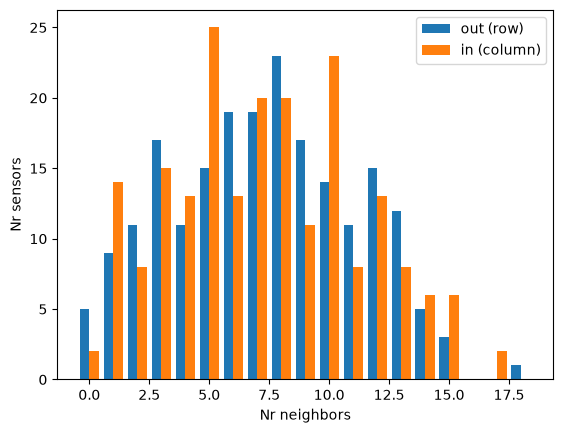

In [4]:
out_deg = np.count_nonzero(adj_mx, axis=1) - 1
in_deg = np.count_nonzero(adj_mx, axis=0) - 1
bins = np.arange(0, max(out_deg.max(), in_deg.max()) + 2) - 0.5
plt.hist([out_deg, in_deg], bins=bins, label=["out (row)", "in (column)"])
plt.xlabel("Nr neighbors")
plt.ylabel("Nr sensors")
plt.legend()
plt.show()

In [5]:
G = nx.from_numpy_array(adj_mx, create_using=nx.DiGraph)
G.remove_edges_from(nx.selfloop_edges(G))
print("Weakly connected components:", nx.number_weakly_connected_components(G))
print("Strongly connected components:", nx.number_strongly_connected_components(G))

Weakly connected components: 2
Strongly connected components: 13


In [6]:
from pyvis.network import Network
net = Network(notebook=True, directed=True, height="700px", cdn_resources="in_line")
net.from_nx(G)
html = net.generate_html(notebook=True)
#with open("hub.html", "w", encoding="utf-8") as f:
#    f.write(html)

#from IPython.display import IFrame
#IFrame("hub.html", width="100%", height="700px")

## Measurements

**Collection**
- Traffic speed (mph), recorded by 207 loop-detector sensors on LA highways
- Period: Mar 2012 to Jun 2012 (~4 months, 119 days)
- Sampling rate: every `5 minutes` (288 readings per day per sensor)

**Data shape**
- Full dataset: `(34272, 207)` = `(time steps, sensors)`
  - 34272 timestamps = 119 days x 288 steps/day
  - Entry `[t, i]` = speed at sensor `i` (same order as the adjacency matrix) at time step `t`
- Timestamps: `(34272, 2)` = `(time of day, day of week)` for each step
  - `time of day` = `step in day / 288` -> i.e. 00:00 -> 0 / 288 = 0; 12:00 -> 144 / 288 = 0.5
  - `day of week` = `nr day / 7` -> i.e. 0, 1/7, ..., 6/7

**Train / val / test split** (chronological, `70-10-20`)

| split | time steps | shape |
|---|---|---|
| train | 23990 | `(23990, 207)` |
| val | 3427 | `(3427, 207)` |
| test | 6855 | `(6855, 207)` |

**Missing values**
- No NaNs; missing readings are stored as `0.0` (`null_val = 0.0` in `meta.json`)
- Zeros: train `7.1%`, val `7.0%`, test `12.1%` -> spread fairly even across sensors
- Usual approach -> skip them when computing errors

In [7]:
datasets = ["train", "val", "test"]
all_data = []
all_timestamps = []
for d in datasets:
    print(f"Processing {d} dataset...")
    timestamps = np.load(os.path.join(data_path, f"{d}_timestamps.npy"))
    data = np.load(os.path.join(data_path, f"{d}_data.npy"))
    all_timestamps.append(timestamps)
    all_data.append(data)
    print(f"Timestamps shape: {timestamps.shape}, dtype: {timestamps.dtype}")
    print(f"Data shape: {data.shape}, dtype: {data.dtype}")
    print("\n\n")

all_timestamps = np.concatenate(all_timestamps)
all_data = np.concatenate(all_data)
print("All_data shape", all_data.shape)
print("All_timestamps shape", all_timestamps.shape)


Processing train dataset...
Timestamps shape: (23990, 2), dtype: float32
Data shape: (23990, 207), dtype: float32



Processing val dataset...
Timestamps shape: (3427, 2), dtype: float32
Data shape: (3427, 207), dtype: float32



Processing test dataset...
Timestamps shape: (6855, 2), dtype: float32
Data shape: (6855, 207), dtype: float32



All_data shape (34272, 207)
All_timestamps shape (34272, 2)


In [8]:
import json
import folium
from branca.element import MacroElement
from jinja2 import Template
from src.data.analysis import get_distance_between_sensors

n_s = len(sensor_ids)
dist_km = np.array([[get_distance_between_sensors(i, j) for j in range(n_s)] for i in range(n_s)]) / 1000

loc = pd.read_csv(os.path.join(data_path, "graph_sensor_locations.csv"))
loc = loc.set_index(loc["sensor_id"].astype(str)).loc[[str(s) for s in sensor_ids]].reset_index(drop=True)

A = adj_mx.copy()
np.fill_diagonal(A, 0)
out_deg = (A > 0).sum(axis=1)
in_deg = (A > 0).sum(axis=0)
zeros = (all_data == 0).sum(axis=0)

sensors = [
    dict(i=i, id=str(sensor_ids[i]), lat=float(loc.latitude[i]), lon=float(loc.longitude[i]),
         din=int(in_deg[i]), dout=int(out_deg[i]), zeros=int(zeros[i]),
         pz=round(100 * zeros[i] / all_data.shape[0], 1))
    for i in range(len(sensor_ids))
]


class SensorLayer(MacroElement):
    _template = Template("""
    {% macro script(this, kwargs) %}
    (function () {
        var map = {{ this._parent.get_name() }};
        var S = {{ this.sensors }};
        var A = {{ this.adj }};
        var Dm = {{ this.dist }};
        function km(i, j) { return isFinite(Dm[i][j]) ? Dm[i][j] + '' : 'unreachable'; }
        var sel = [], line = null, markers = [];

        var panel = L.control({position: 'topright'});
        panel.onAdd = function () {
            var div = L.DomUtil.create('div');
            div.style.cssText = 'background:white;padding:8px;font:13px sans-serif;max-width:260px';
            div.innerHTML = 'Sensor idx: <input id="s1" size="4"> <input id="s2" size="4"> ' +
                '<button id="go">Select</button><div id="out">Click 2 sensors or type 2 indices</div>';
            L.DomEvent.disableClickPropagation(div);
            return div;
        };
        panel.addTo(map);
        var out = document.getElementById('out');

        function style(k, color) { markers[k].setStyle({color: color, fillColor: color}); }

        function reset() {
            sel.forEach(function (k) { style(k, '#1f77b4'); });
            sel = [];
            if (line) { map.removeLayer(line); line = null; }
        }

        function pick(k) {
            if (sel.length == 2) reset();
            sel.push(k);
            style(k, 'red');
            if (sel.length == 1) {
                out.innerHTML = 'Selected: ' + S[k].id + ' (idx ' + k + ')<br>Pick another sensor';
            } else {
                var a = S[sel[0]], b = S[sel[1]];
                line = L.polyline([[a.lat, a.lon], [b.lat, b.lon]], {color: 'red', weight: 2}).addTo(map);
                out.innerHTML = '<b>' + a.i + ' &rarr; ' + b.i + '</b>: ' + A[a.i][b.i] +
                    '<br><b>' + b.i + ' &rarr; ' + a.i + '</b>: ' + A[b.i][a.i] +
                    '<br>road dist ' + a.i + ' &rarr; ' + b.i + ': ' + km(a.i, b.i) +
                    '<br>road dist ' + b.i + ' &rarr; ' + a.i + ': ' + km(b.i, a.i);
            }
        }

        S.forEach(function (s, k) {
            var mk = L.circleMarker([s.lat, s.lon], {radius: 6, color: '#1f77b4', fillOpacity: 0.8});
            mk.bindTooltip('sensor ' + s.id + ' (idx ' + s.i + ')<br>in-neighbors: ' + s.din +
                '<br>out-neighbors: ' + s.dout + '<br>zero obs: ' + s.zeros + ' (' + s.pz + '%)');
            mk.on('click', function () { pick(k); });
            mk.addTo(map);
            markers.push(mk);
        });

        document.getElementById('go').onclick = function () {
            var a = parseInt(document.getElementById('s1').value);
            var b = parseInt(document.getElementById('s2').value);
            if (isNaN(a) || isNaN(b) || a < 0 || b < 0 || a >= S.length || b >= S.length) {
                out.innerHTML = 'Enter two indices between 0 and ' + (S.length - 1);
                return;
            }
            reset();
            pick(a);
            pick(b);
            map.fitBounds([[S[a].lat, S[a].lon], [S[b].lat, S[b].lon]], {maxZoom: 14, padding: [60, 60]});
        };
    })();
    {% endmacro %}
    """)

    def __init__(self, sensors, adj, dist):
        super().__init__()
        self._name = "SensorLayer"
        self.sensors = json.dumps(sensors)
        self.adj = json.dumps(np.round(adj, 4).tolist())
        self.dist = json.dumps(np.round(dist, 2).tolist())


m = folium.Map(location=[loc.latitude.mean(), loc.longitude.mean()], zoom_start=11, tiles="OpenStreetMap")
m.fit_bounds([[loc.latitude.min(), loc.longitude.min()], [loc.latitude.max(), loc.longitude.max()]])
m.add_child(SensorLayer(sensors, adj_mx, dist_km))
m.save("notebooks/plots/sensor_map.html")

In [9]:
for split in datasets:
    data = np.load(os.path.join(data_path, f"{split}_data.npy"))
    zeros = (data == 0).sum()
    print(f"{split}: shape {data.shape}, zeros {zeros} ({zeros / data.size:.1%})")

train: shape (23990, 207), zeros 354180 (7.1%)
val: shape (3427, 207), zeros 49389 (7.0%)
test: shape (6855, 207), zeros 171733 (12.1%)


In [10]:
#missing values
print("min", (np.where(all_data == 0, 1, 0).sum(axis = 0) / all_data.shape[0] * 100).min(), "%")
print("max", (np.where(all_data == 0, 1, 0).sum(axis = 0) / all_data.shape[0] * 100).max(), "%")
print("mean", (np.where(all_data == 0, 1, 0).sum(axis = 0) / all_data.shape[0] * 100).mean(), "%")


min 6.26750700280112 %
max 20.10387488328665 %
mean 8.109350825676486 %


In [11]:
print(np.min(all_data)) 
print(np.max(all_data))
print(np.mean(all_data))

0.0
70.0
53.71902


# EDA

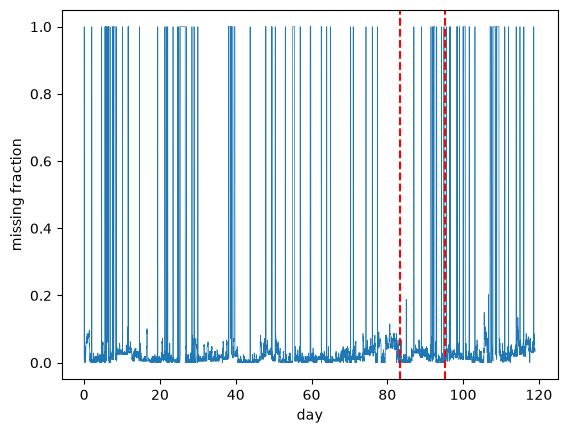

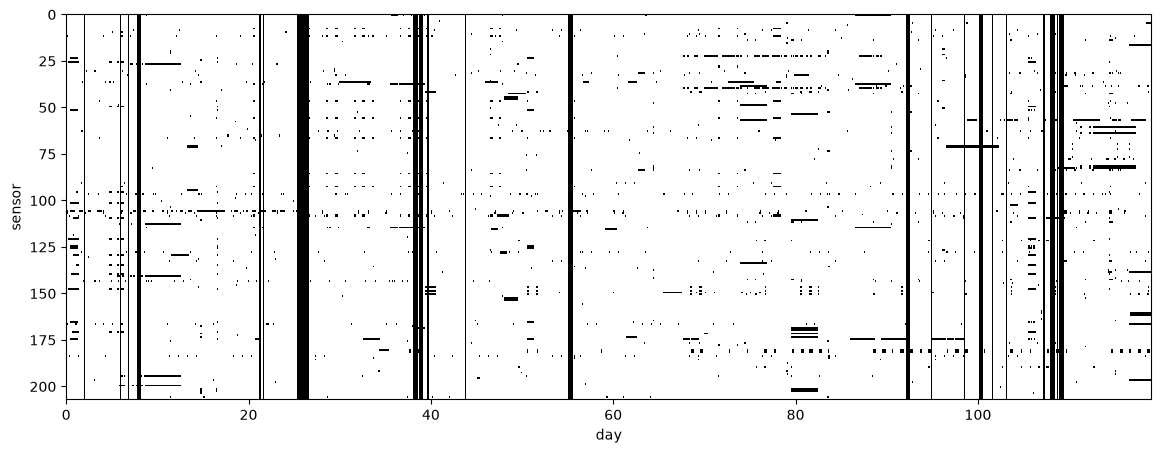

In [12]:
missing = all_data == 0
frac_t = missing.mean(axis=1)
plt.plot(np.arange(len(frac_t)) / 288, frac_t, lw=0.5)
for n in (23990, 23990 + 3427):
    plt.axvline(n / 288, color="r", ls="--")
plt.xlabel("day")
plt.ylabel("missing fraction")
plt.show()
plt.figure(figsize=(14, 5))
plt.imshow(missing.T, aspect="auto", cmap="gray_r", interpolation="nearest",
           extent=[0, missing.shape[0] / 288, missing.shape[1], 0])
plt.xlabel("day")
plt.ylabel("sensor")
plt.show()

## PATTERNS OVER TIME

In [13]:
data_nan = np.where(all_data == 0, np.nan, all_data)
df = pd.DataFrame(data_nan)
df["time_of_day"] = pd.Series(all_timestamps[:,0])
df["day_of_week"] = pd.Series(all_timestamps[:,1])
df

,0,1,2,3,4,5,6,7,8,9,...,199,200,201,202,203,204,205,206,time_of_day,day_of_week
0,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125000,67.125000,59.625000,62.750000,...,64.500000,66.428574,66.875000,59.375000,69.000000,59.250000,69.000000,61.875000,0.000000,0.428571
1,62.666668,68.555557,65.444443,62.444443,64.444443,68.111115,65.000000,65.000000,57.444443,63.333332,...,66.666664,58.555557,62.000000,61.111111,64.444443,55.888889,68.444443,62.875000,0.003472,0.428571
2,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500000,64.250000,63.875000,65.375000,...,56.500000,59.250000,68.125000,62.500000,65.625000,61.375000,69.857140,62.000000,0.006944,0.428571
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.010417,0.428571
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.013889,0.428571
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34267,65.000000,65.888885,68.555557,61.666668,NaN,54.555557,62.444443,63.333332,59.222221,65.333336,...,65.111115,55.666668,66.333336,62.444443,66.777779,64.888885,69.666664,62.333332,0.982639,0.285714
34268,61.375000,65.625000,66.500000,62.750000,NaN,50.500000,62.000000,67.000000,65.250000,67.125000,...,60.125000,60.500000,67.250000,59.375000,66.000000,61.250000,69.000000,62.000000,0.986111,0.285714
34269,67.000000,59.666668,69.555557,61.000000,NaN,44.777779,64.222221,63.777779,59.777779,57.666668,...,64.333336,57.000000,66.000000,62.666668,68.666664,63.333332,67.444443,61.222221,0.989583,0.285714
34270,66.750000,62.250000,66.000000,59.625000,NaN,53.000000,64.285713,64.125000,60.875000,66.250000,...,61.625000,60.500000,65.625000,66.375000,69.500000,63.000000,67.875000,63.500000,0.993056,0.285714


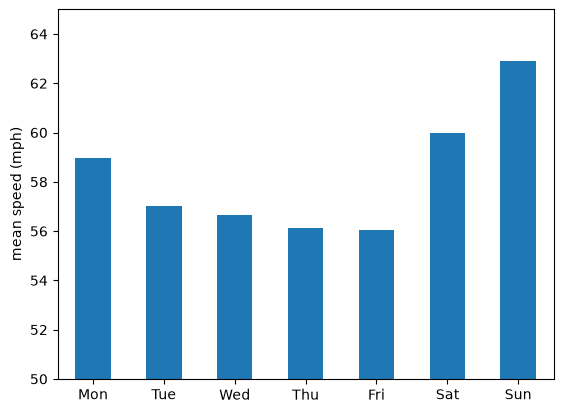

In [14]:
average_day_of_week = df.groupby(["day_of_week"]).mean(skipna=True).mean(axis = 1)
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
average_day_of_week.index = average_day_of_week.index.map(lambda x : days[int(round(x * 7))])
average_day_of_week.plot.bar(rot=0, ylim=(50, 65))
plt.ylabel("mean speed (mph)")
plt.xlabel("")
plt.show()

We can see pretty clearly that traffic is **faster on the weekend** => less congestion on weekends

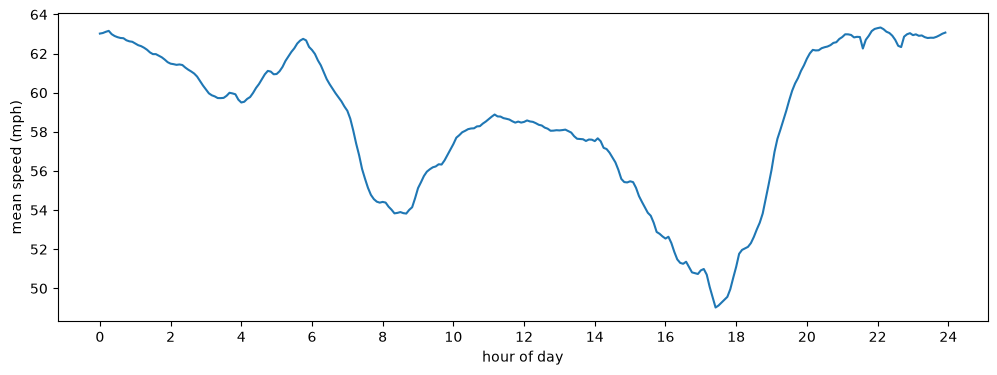

In [15]:
sensor_cols = [c for c in df.columns if c not in ("day_of_week", "time_of_day")]

avg_tod = df.groupby("time_of_day")[sensor_cols].mean().mean(axis=1)
avg_tod.index = avg_tod.index * 24 #transform to hours

avg_tod.plot(figsize=(12, 4))
plt.xlabel("hour of day")
plt.ylabel("mean speed (mph)")
plt.xticks(range(0, 25, 2))
plt.show()

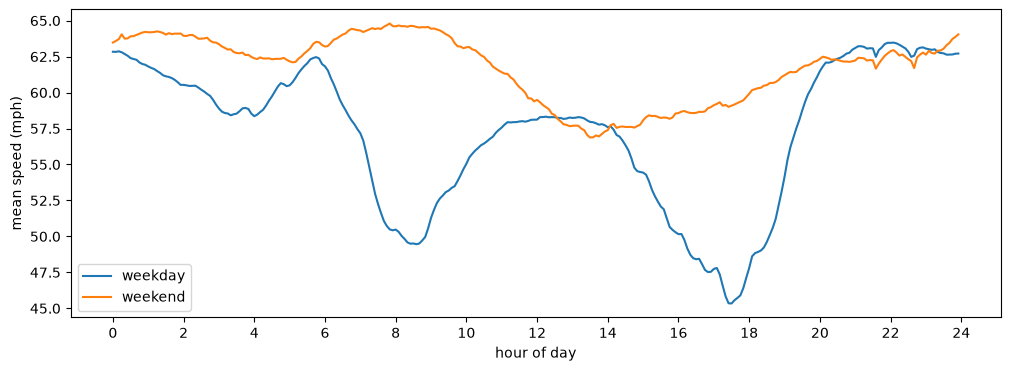

In [16]:
is_weekend = round(df["day_of_week"] * 7) >= 5
for name, sub in [("weekday", df[~is_weekend]), ("weekend", df[is_weekend])]:
    s = sub.groupby("time_of_day")[sensor_cols].mean().mean(axis=1)
    s.index = s.index * 24
    s.plot(figsize=(12, 4), label=name)

    
plt.xlabel("hour of day")
plt.ylabel("mean speed (mph)")
plt.xticks(range(0, 25, 2))
plt.legend()
plt.show()

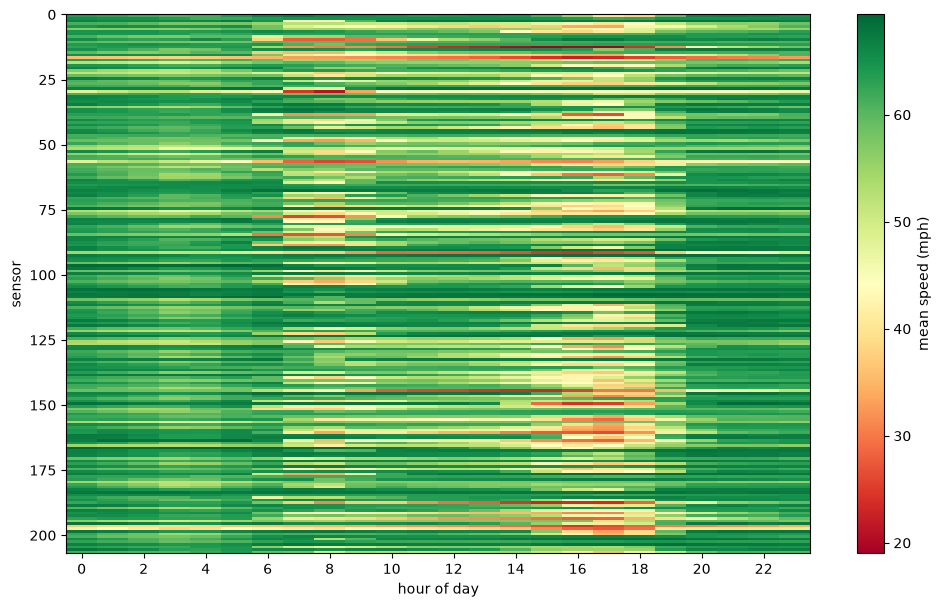

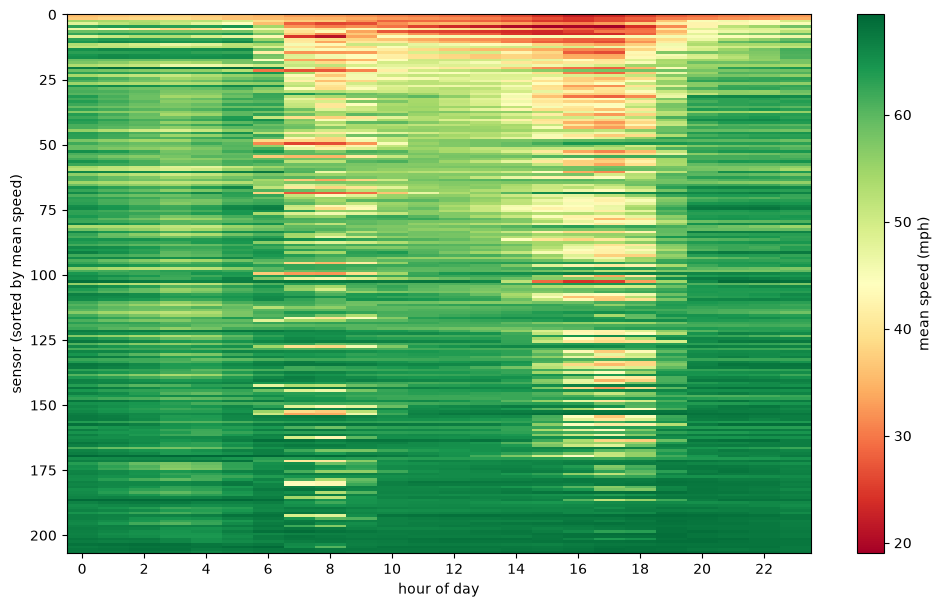

In [17]:
sensor_cols = [c for c in df.columns if c not in ("day_of_week", "time_of_day")]
hour = np.round(df["time_of_day"] * 288).astype(int) // 12

heat = df[sensor_cols].groupby(hour).mean().T

plt.figure(figsize=(12, 7))
plt.imshow(heat, aspect="auto", cmap="RdYlGn", interpolation="nearest",
           extent=[-0.5, 23.5, heat.shape[0], 0])
plt.colorbar(label="mean speed (mph)")
plt.xlabel("hour of day")
plt.ylabel("sensor")
plt.xticks(range(0, 24, 2))
plt.show()

heat_sorted = heat.loc[heat.mean(axis=1).sort_values().index]

plt.figure(figsize=(12, 7))
plt.imshow(heat_sorted, aspect="auto", cmap="RdYlGn", interpolation="nearest",
           extent=[-0.5, 23.5, heat_sorted.shape[0], 0])
plt.colorbar(label="mean speed (mph)")
plt.xlabel("hour of day")
plt.ylabel("sensor (sorted by mean speed)")
plt.xticks(range(0, 24, 2))
plt.show()


## Spatial Correlation

In [18]:
# correlation between sensors
sensor_cols = [c for c in df.columns if c not in ("day_of_week", "time_of_day")]
corr = df[sensor_cols].corr(min_periods = 1000)
corr

,0,1,2,3,4,5,6,7,8,9,...,197,198,199,200,201,202,203,204,205,206
0,1.000000,0.319392,-0.064807,0.382533,0.211557,0.302798,0.441745,0.279205,-0.086955,-0.142337,...,0.429655,0.667209,0.599703,-0.029460,-0.048173,0.034592,0.005356,0.164438,0.393581,0.290393
1,0.319392,1.000000,0.069116,0.182123,0.052631,0.137654,0.200133,0.413108,0.097857,0.011894,...,0.191978,0.321265,0.296733,0.118129,0.089343,0.185394,0.171684,0.111528,0.194187,0.073875
2,-0.064807,0.069116,1.000000,0.097519,0.166382,0.077524,-0.119777,0.103709,0.395933,0.587946,...,0.087378,-0.069570,-0.000082,-0.060306,0.439757,-0.058178,0.020451,0.494704,-0.024058,0.112364
3,0.382533,0.182123,0.097519,1.000000,0.518937,0.688498,0.462036,0.297274,-0.042033,0.129468,...,0.420649,0.503642,0.424509,-0.248937,-0.054086,-0.028346,-0.053855,0.372121,0.296736,0.367618
4,0.211557,0.052631,0.166382,0.518937,1.000000,0.269880,0.524724,0.270911,-0.072070,0.271587,...,0.421376,0.340505,0.277356,-0.390381,-0.059557,-0.081650,-0.115982,0.519557,0.254154,0.464792
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202,0.034592,0.185394,-0.058178,-0.028346,-0.081650,0.005527,0.010555,0.140418,0.120985,-0.015201,...,0.041354,0.003011,0.061247,0.312737,0.147561,1.000000,0.349675,-0.019680,0.042666,-0.045283
203,0.005356,0.171684,0.020451,-0.053855,-0.115982,-0.000122,-0.044727,0.118597,0.121401,0.013416,...,0.017769,-0.042563,0.009058,0.264485,0.179536,0.349675,1.000000,-0.023068,-0.005783,-0.067029
204,0.164438,0.111528,0.494704,0.372121,0.519557,0.204493,0.264586,0.258950,0.242299,0.627628,...,0.383949,0.224266,0.260548,-0.213978,0.236309,-0.019680,-0.023068,1.000000,0.181628,0.325704
205,0.393581,0.194187,-0.024058,0.296736,0.254154,0.175017,0.424593,0.233088,-0.053893,-0.070937,...,0.386831,0.440001,0.602892,-0.065224,-0.035023,0.042666,-0.005783,0.181628,1.000000,0.262238


In [19]:
# minimum hops between sensors
from scipy.sparse.csgraph import shortest_path

A = (adj_mx > 0).astype(float)
np.fill_diagonal(A, 0)

hops, pred = shortest_path(A, directed=True, unweighted=True, return_predecessors=True)

def get_path(i, j):
    if np.isinf(hops[i, j]):
        return None
    path = [j]
    while path[-1] != i:
        path.append(pred[i, path[-1]])
    return path[::-1]

hops

array([[ 0.,  4.,  4., ...,  6.,  4.,  5.],
       [ 5.,  0.,  1., ..., 10.,  8.,  9.],
       [ 4.,  1.,  0., ...,  9.,  7.,  8.],
       ...,
       [ 5.,  9.,  9., ...,  0.,  5.,  6.],
       [ 4.,  8.,  8., ...,  4.,  0.,  5.],
       [ 4.,  5.,  6., ...,  7.,  3.,  0.]], shape=(207, 207))

unreachable pairs: 228 mean corr: 0.19808127443388412
all pairs mean corr: 0.2117248172405224
          mean    median       std  count
hops                                     
1     0.457047  0.457844  0.285538   1313
2     0.282198  0.267083  0.213975   2069
3     0.234796  0.214398  0.195713   2469
4     0.215579  0.189048  0.203702   2696
5     0.206166  0.180557  0.209344   3054
6     0.193337  0.167812  0.208568   3058
7     0.161306  0.141920  0.216366   2221
8     0.141336  0.129055  0.222450   1594
9     0.137477  0.127943  0.227234   1231
10    0.108427  0.106028  0.208643   1388


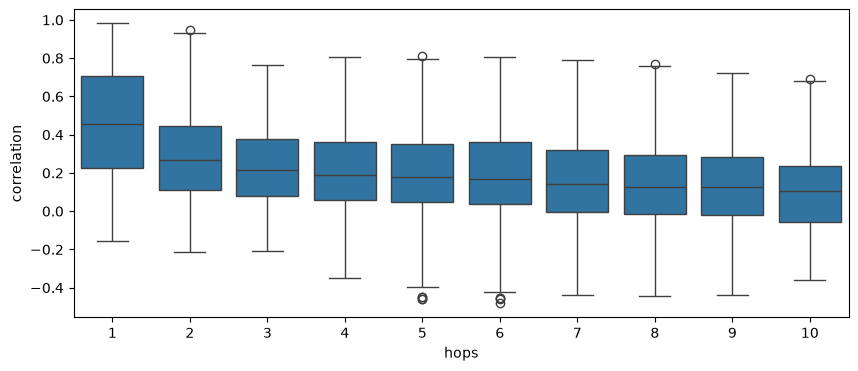

In [20]:
import seaborn as sns

n_sensors = hops.shape[0]
h = np.minimum(hops, hops.T)
iu = np.triu_indices(n_sensors, 1)
d = pd.DataFrame({"hops": h[iu], "corr": corr.values[iu]}).dropna()

unreach = np.isinf(d["hops"])
print("unreachable pairs:", unreach.sum(), "mean corr:", d.loc[unreach, "corr"].mean())
print("all pairs mean corr:", d["corr"].mean())

d = d[~unreach]
d["hops"] = d["hops"].astype(int).clip(upper=10)

print(d.groupby("hops")["corr"].agg(["mean", "median", "std", "count"]))

plt.figure(figsize=(10, 4))
sns.boxplot(x="hops", y="corr", data=d)
plt.xlabel("hops")
plt.ylabel("correlation")
plt.show()

In [21]:
# similar sensors not connected in the graph
# use corr[i, j] and hops[i, j]
iu = np.triu_indices(corr.shape[0], 1)
h = np.minimum(hops, hops.T)[iu]
c = corr.values[iu]
mask = np.isinf(h) & (c >= 0.4)  #not connected but with high correlation
pairs = list(zip(iu[0][mask], iu[1][mask], c[mask]))
pairs

[(np.int64(4), np.int64(26), np.float64(0.42038389876453797)),
 (np.int64(6), np.int64(26), np.float64(0.6063171625207024)),
 (np.int64(12), np.int64(26), np.float64(0.4047159018620653)),
 (np.int64(15), np.int64(26), np.float64(0.41610746320275777)),
 (np.int64(16), np.int64(26), np.float64(0.5456130825838642)),
 (np.int64(19), np.int64(26), np.float64(0.5762932293005445)),
 (np.int64(24), np.int64(26), np.float64(0.4465975337366283)),
 (np.int64(26), np.int64(33), np.float64(0.4653950437562759)),
 (np.int64(26), np.int64(34), np.float64(0.42113481082336557)),
 (np.int64(26), np.int64(37), np.float64(0.4350599106615236)),
 (np.int64(26), np.int64(39), np.float64(0.50808588088675)),
 (np.int64(26), np.int64(42), np.float64(0.49774985120820864)),
 (np.int64(26), np.int64(54), np.float64(0.47420910388743814)),
 (np.int64(26), np.int64(57), np.float64(0.5602157780389645)),
 (np.int64(26), np.int64(61), np.float64(0.440215566543417)),
 (np.int64(26), np.int64(63), np.float64(0.418535930144

Sensor 26 is isolated, not connected to anything => ignore it  
Sensors (152, 178), (153, 202), (179, 202) are indeed on the same way but don t have an edge between them. These were the only pairs unconnected with corr >= 0.4. => unnecessary to add edge (only 3 more edges).

                    mean    median  count
(0.099, 0.157]  0.355932  0.340207    303
(0.157, 0.246]  0.369216  0.359274    303
(0.246, 0.409]  0.375229  0.365344    303
(0.409, 0.655]  0.450702  0.451472    303
(0.655, 1.0]    0.694097  0.798221    303


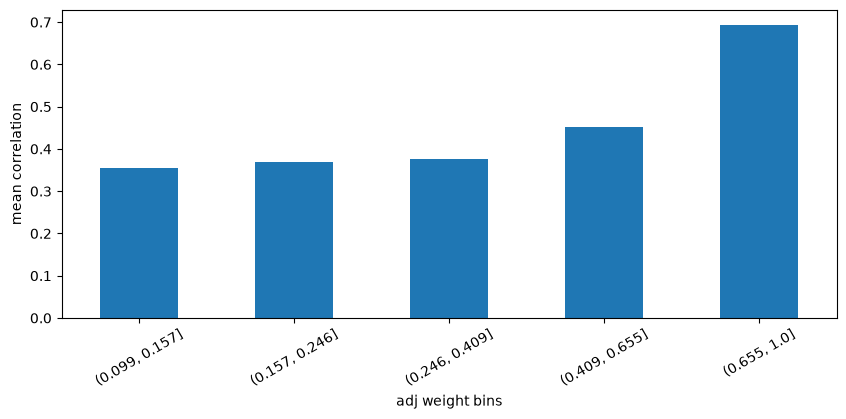

In [22]:
n_sensors = adj_mx.shape[0]
edge = (adj_mx > 0) & ~np.eye(n_sensors, dtype=bool)
i, j = np.where(edge)
w = adj_mx[i, j]
c = corr.values[i, j]
bins = pd.qcut(w, 5)
table = pd.Series(c).groupby(bins).agg(["mean", "median", "count"])
print(table)
plt.figure(figsize=(10, 4))
pd.Series(c).groupby(bins).mean().plot.bar(rot=30)
plt.ylabel("mean correlation")
plt.xlabel("adj weight bins")
plt.show()

## Spatial propagation
Implemented a function to return the distance between 2 sensors

In [23]:
from src.data.analysis import get_distance_between_sensors
get_distance_between_sensors(73, 203)

np.float32(20569.7)

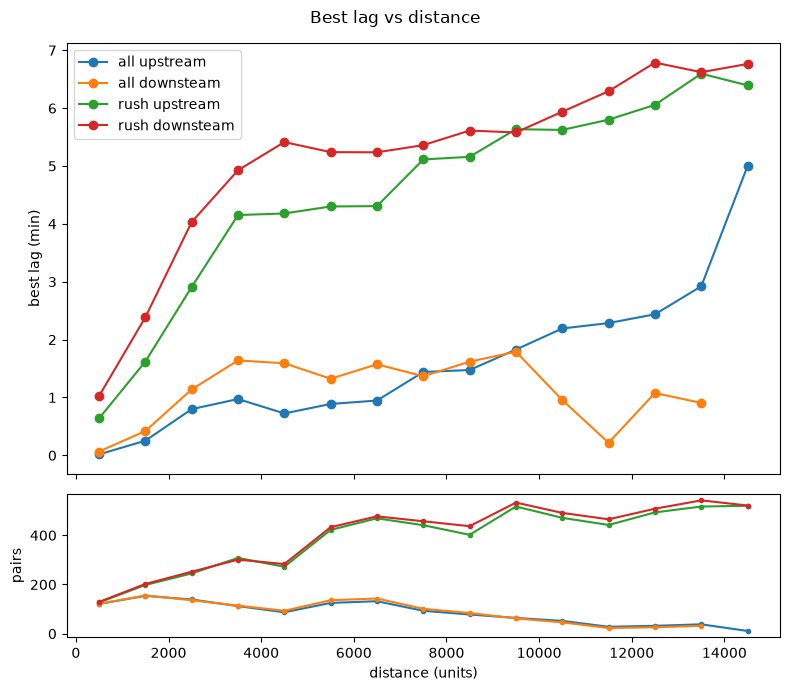

In [25]:
def lagged_corr(df, rows=None):
    sensors = [c for c in df.columns if c not in ("time_of_day", "day_of_week")]
    X = df[sensors]
    # substract the mean per time of day and day of week to detrend
    # lag 0 will always be very correlated otherwise because of temporal trend
    residual = X - X.groupby([df["time_of_day"], df["day_of_week"]]).transform("mean")

    # z-score normalize so that the correlation is just a product between the series divided by nr valid obs
    # corr = ((x - x.mean())(y - y.mean())).mean() / (x.std() * y.std())
    # corr = (((x - x.mean()) / x.std()) * ((y - y.mean()) / y.std())).mean()
    Z = (residual - residual.mean()) / residual.std()
    if rows is not None:
        Z[~rows] = np.nan
    M = (~Z.isna()).to_numpy(float)
    Z = Z.fillna(0).to_numpy()
    max_lag = 12 # 1h
    C = np.zeros((max_lag + 1, Z.shape[1], Z.shape[1])) # (13, 207, 207) correlations between sensors at each lag
    for lag in range(max_lag + 1):
        a, b = (Z, Z) if lag == 0 else (Z[:-lag], Z[lag:])
        ma, mb = (M, M) if lag == 0 else (M[:-lag], M[lag:])
        C[lag] = (a.T @ b) / np.maximum(ma.T @ mb, 1)
    return C

def peak_lag(C):
    return C.argmax(axis=0), C.max(axis=0)

def pairs(C, D, min_peak=0.3, reverse=False):
    lag, peak = peak_lag(C)
    if reverse:
        lag, peak = lag.T, peak.T
    m = np.isfinite(D) & (D > 0) & (peak > min_peak)
    return D[m], lag[m]

def plot_binned(ax, dist_m, lag_min, label, max_m=15000, bin_m=1000, min_n=10):
    d = pd.DataFrame({"m": dist_m, "lag": lag_min})
    d["bin"] = pd.cut(d["m"], np.arange(0, max_m + 1, bin_m))
    g = d.groupby("bin", observed=True)["lag"]
    n = g.count()
    keep = n >= min_n
    x = np.array([b.mid for b in n.index])[keep.values]
    mean = g.mean()[keep]
    ax.plot(x, mean, marker="o", label=label)
    return x, n[keep]

rush = ((df["time_of_day"] * 24).between(7, 9) | (df["time_of_day"] * 24).between(16, 19)) & (df["day_of_week"] < 0.7)
sets = {"all": None, "rush": rush}

fig, (ax, axn) = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
n_sensors = adj_mx.shape[0]
D = np.array([[get_distance_between_sensors(i, j) for j in range(n_sensors)] for i in range(n_sensors)])

for name, rows in sets.items():
    C = lagged_corr(df, rows)
    for rev, d in ((False, "upstream"), (True, "downsteam")):
        x, cnt = plot_binned(ax, *pairs(C, D, reverse=rev), label=f"{name} {d}")
        axn.plot(x, cnt, marker=".", label=f"{name} {d}")
ax.set_ylabel("best lag (min)")
ax.legend()
axn.set_xlabel("distance (units)")
axn.set_ylabel("pairs")
fig.suptitle("Best lag vs distance")
plt.tight_layout()
plt.show()